In [ ]:
#Business problem statement

'''Organisations handling large volume of handwritten document
Like postal services banks educational institution government offices which needs to:
automatically recognise and return English alphabets
manual processing of handwritten form is:
time consuming
error prone
expensive
operationly inefficient
automatic letter recognition improves efficiency and accuracy in document processing system '''

#Business objective

'''Build model to accurately classify handwritten letters a to z
identify key geometric features influencing letter recognition
develop an automated system for character recognition
improve document system for character recognition improved document digitisation accuracy
reduce human intervention in data entry processes'''

'Build model to accurately classify handwritten letters a to z\nidentify key geometric features influencing letter recognition\ndevelop an automated system for character recognition\nimprove document system for character recognition improved document digitisation accuracy\nreduce human intervention in data entry processes'

In [ ]:
#Motivation
'''Understanding handwritten letter patterns helps automate postal code reading digitise
 exam papers and answer sheets
enable bank cheque processing improve ocr systems
 supports AI base document automation
 reduce operational processing cost'''

'Understanding handwritten letter patterns helps automate postal code reading digitise\n exam papers and answer sheets\nenable bank cheque processing improve ocr systems\n supports AI base document automation\n reduce operational processing cost'

In [ ]:
#constraints

'''Multi class classification problem some letters may have similar shapes noise and handwriting variations may affect accuracy model mein
required tuning for optimal performance large features space may increase computational cost over fitting risk in complex models '''

#Success criteria
'''Business success criteria is high accuracy in letter recognition reduce the normal verification workload
Fastrack document digitisation reliable deployment in ocr system improved operational efficiency'''

#Machine learning success criteria is
''' high classification accuracy balance performance across all 26 classes storage precision and recall per class confusion
Matrix shows minimal miss classification cross validation stability no severe over fitting'''

' high classification accuracy balance performance across all 26 classes storage precision and recall per class confusion\nMatrix shows minimal miss classification cross validation stability no severe over fitting'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [ ]:
letter=pd.read_csv("/content/letterdata.csv")
print("shape of dataset:",letter.shape)
print(letter.head())

shape of dataset: (20000, 17)
  letter  xbox  ybox  width  height  onpix  xbar  ybar  x2bar  y2bar  xybar  \
0      T     2     8      3       5      1     8    13      0      6      6   
1      I     5    12      3       7      2    10     5      5      4     13   
2      D     4    11      6       8      6    10     6      2      6     10   
3      N     7    11      6       6      3     5     9      4      6      4   
4      G     2     1      3       1      1     8     6      6      6      6   

   x2ybar  xy2bar  xedge  xedgey  yedge  yedgex  
0      10       8      0       8      0       8  
1       3       9      2       8      4      10  
2       3       7      3       7      3       9  
3       4      10      6      10      2       8  
4       5       9      1       7      5      10  


In [ ]:
print("\ndata types:\n",letter.dtypes)
print("\nsummary statistics\n",letter.describe())
print("\nmissing values\n",letter.isnull().sum())


data types:
 letter    object
xbox       int64
ybox       int64
width      int64
height     int64
onpix      int64
xbar       int64
ybar       int64
x2bar      int64
y2bar      int64
xybar      int64
x2ybar     int64
xy2bar     int64
xedge      int64
xedgey     int64
yedge      int64
yedgex     int64
dtype: object

summary statistics
                xbox          ybox         width       height         onpix  \
count  20000.000000  20000.000000  20000.000000  20000.00000  20000.000000   
mean       4.023550      7.035500      5.121850      5.37245      3.505850   
std        1.913212      3.304555      2.014573      2.26139      2.190458   
min        0.000000      0.000000      0.000000      0.00000      0.000000   
25%        3.000000      5.000000      4.000000      4.00000      2.000000   
50%        4.000000      7.000000      5.000000      6.00000      3.000000   
75%        5.000000      9.000000      6.000000      7.00000      5.000000   
max       15.000000     15.000000     


class distribution:
 letter
U    813
D    805
P    803
T    796
M    792
A    789
X    787
Y    786
N    783
Q    783
F    775
G    773
E    768
B    766
V    764
L    761
R    758
I    755
O    753
W    752
S    748
J    747
K    739
C    736
H    734
Z    734
Name: count, dtype: int64


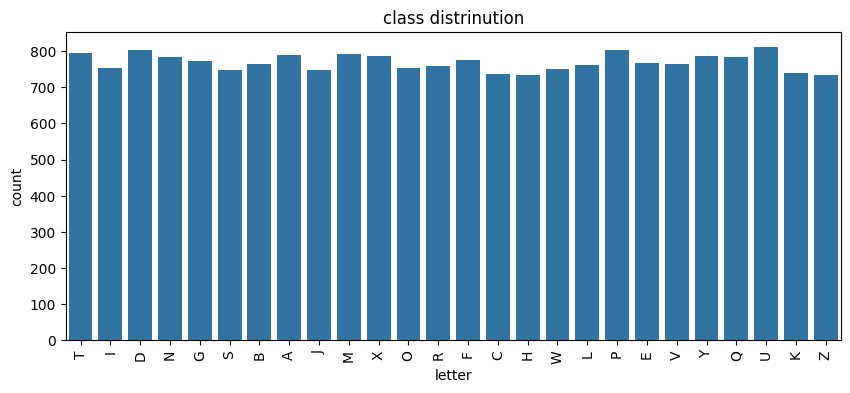

In [ ]:
print("\nclass distribution:\n",letter['letter'].value_counts())
plt.figure(figsize=(10,4))
sns.countplot(x='letter',data=letter)
plt.xticks(rotation=90)
plt.title("class distrinution")
plt.show()

In [ ]:
print("\Mean:\n",letter.mean(numeric_only=True))
print("\nVariance:\n",letter.var(numeric_only=True))
print("\nskewness:\n",letter.skew(numeric_only=True))
print("\nkurtosis:\n",letter.kurt(numeric_only=True))

\Mean:
 xbox      4.02355
ybox      7.03550
width     5.12185
height    5.37245
onpix     3.50585
xbar      6.89760
ybar      7.50045
x2bar     4.62860
y2bar     5.17865
xybar     8.28205
x2ybar    6.45400
xy2bar    7.92900
xedge     3.04610
xedgey    8.33885
yedge     3.69175
yedgex    7.80120
dtype: float64

Variance:
 xbox       3.660378
ybox      10.920086
width      4.058506
height     5.113887
onpix      4.798106
xbar       4.104819
ybar       5.407270
x2bar      7.289827
y2bar      5.668318
xybar      6.192507
x2ybar     6.922530
xy2bar     4.328975
xedge      5.440747
xedgey     2.392350
yedge      6.589861
yedgex     2.616209
dtype: float64

skewness:
 xbox      0.715056
ybox     -0.227967
width     0.234941
height   -0.278249
onpix     0.943373
xbar     -0.310079
ybar      0.093471
x2bar     1.159975
y2bar     0.286934
xybar     0.090078
x2ybar    0.288168
xy2bar    0.273728
xedge     1.057288
xedgey    0.049198
yedge     0.468343
yedgex   -0.199507
dtype: float64

kurtosis:


<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:1: SyntaxWarning: invalid escape sequence '\M'
/tmp/ipykernel_1429/169506979.py:1: SyntaxWarning: invalid escape sequence '\M'
  print("\Mean:\n",letter.mean(numeric_only=True))


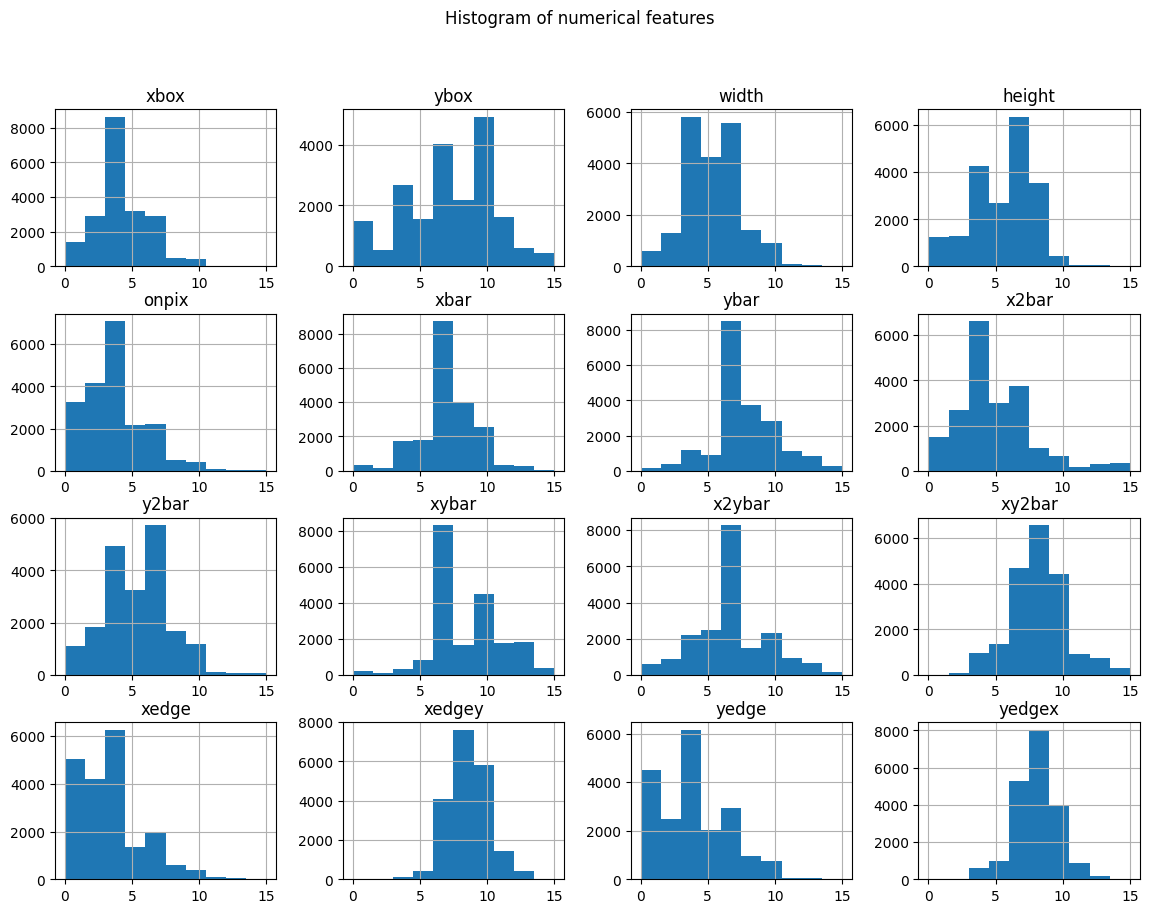

In [ ]:
letter.hist(figsize=(14,10))
plt.suptitle("Histogram of numerical features")
plt.show()

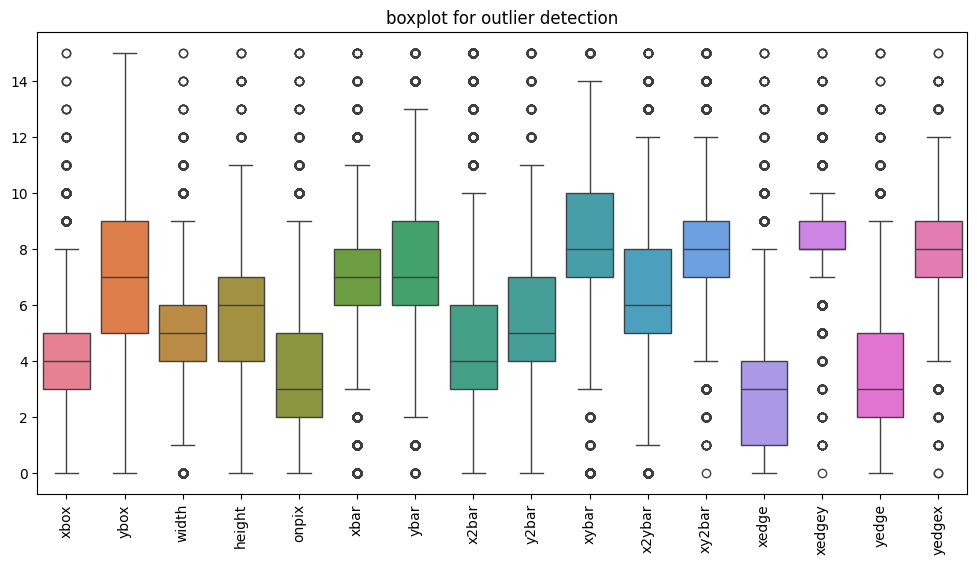

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=letter.drop(columns=['letter']))
plt.xticks(rotation=90)
plt.title("boxplot for outlier detection")
plt.show()

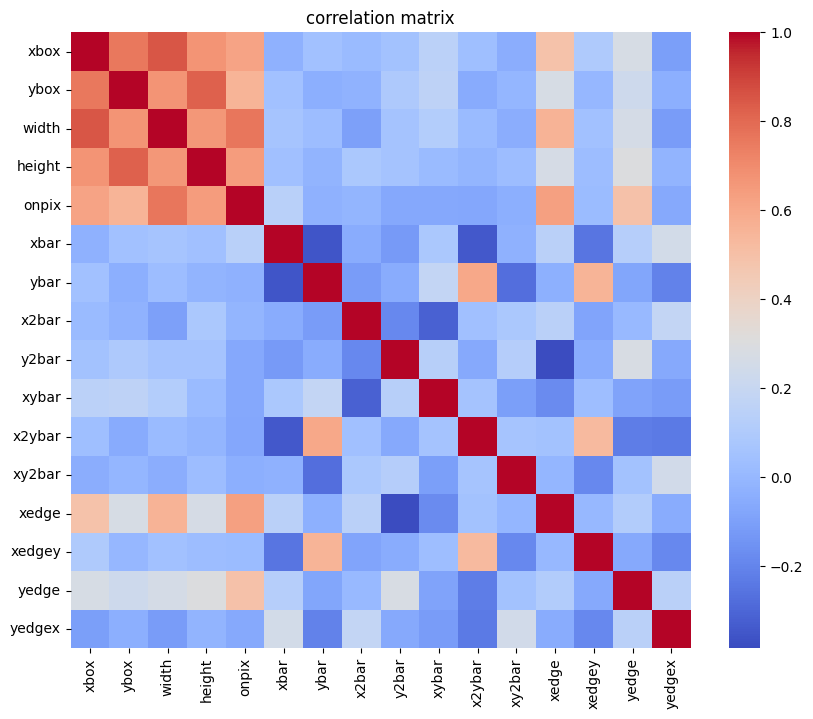

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(letter.drop(columns=['letter']).corr(),cmap='coolwarm')
plt.title("correlation matrix")
plt.show()

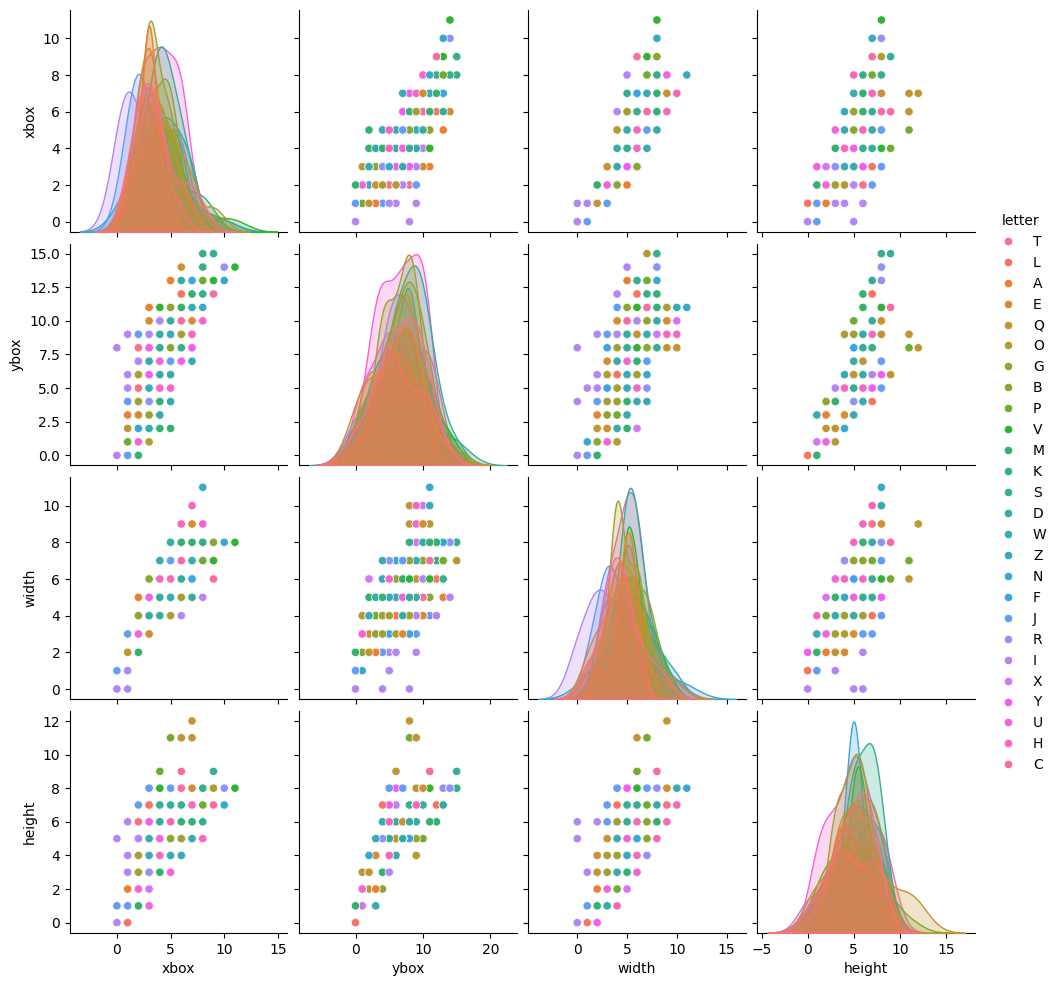

In [ ]:
sample_data=letter.sample(500,random_state=42)
sns.pairplot(sample_data,hue='letter',vars=letter.columns[1:5])
plt.show()

In [ ]:
x=letter.drop(columns=['letter'])
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
print("\nmean after scaling:",np.round(np.mean(x_scaled,axis=0),4))
print("\nstd after scaling:",np.round(np.std(x_scaled,axis=0),4))


mean after scaling: [-0.  0. -0.  0. -0.  0.  0.  0. -0.  0.  0. -0. -0. -0.  0.  0.]

std after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split

In [ ]:
df=pd.read_csv("/content/letterdata.csv")
print("initial shape:",df.shape)
print(df.head())

initial shape: (20000, 17)
  letter  xbox  ybox  width  height  onpix  xbar  ybar  x2bar  y2bar  xybar  \
0      T     2     8      3       5      1     8    13      0      6      6   
1      I     5    12      3       7      2    10     5      5      4     13   
2      D     4    11      6       8      6    10     6      2      6     10   
3      N     7    11      6       6      3     5     9      4      6      4   
4      G     2     1      3       1      1     8     6      6      6      6   

   x2ybar  xy2bar  xedge  xedgey  yedge  yedgex  
0      10       8      0       8      0       8  
1       3       9      2       8      4      10  
2       3       7      3       7      3       9  
3       4      10      6      10      2       8  
4       5       9      1       7      5      10  


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   letter  20000 non-null  object
 1   xbox    20000 non-null  int64 
 2   ybox    20000 non-null  int64 
 3   width   20000 non-null  int64 
 4   height  20000 non-null  int64 
 5   onpix   20000 non-null  int64 
 6   xbar    20000 non-null  int64 
 7   ybar    20000 non-null  int64 
 8   x2bar   20000 non-null  int64 
 9   y2bar   20000 non-null  int64 
 10  xybar   20000 non-null  int64 
 11  x2ybar  20000 non-null  int64 
 12  xy2bar  20000 non-null  int64 
 13  xedge   20000 non-null  int64 
 14  xedgey  20000 non-null  int64 
 15  yedge   20000 non-null  int64 
 16  yedgex  20000 non-null  int64 
dtypes: int64(16), object(1)
memory usage: 2.6+ MB


In [ ]:
print("\nmissing value:\n",df.isnull().sum())


missing value:
 letter    0
xbox      0
ybox      0
width     0
height    0
onpix     0
xbar      0
ybar      0
x2bar     0
y2bar     0
xybar     0
x2ybar    0
xy2bar    0
xedge     0
xedgey    0
yedge     0
yedgex    0
dtype: int64


In [ ]:
df.drop_duplicates(inplace=True)
print("shape after duplicate removed:",df.shape)


shape after duplicate removed: (18668, 17)


In [ ]:
x=df.drop(columns=['letter'])
y=df['letter']

In [ ]:
le=LabelEncoder()
y_encoded=le.fit_transform(y)

In [ ]:
selector=VarianceThreshold(threshold=0.0)
x_var=selector.fit_transform(x)
print("shape after variance filtering:",x_var.shape)

shape after variance filtering: (18668, 16)


In [ ]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x_var)

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(
    x_scaled,y_encoded,test_size=0.2,random_state=42,stratify=y_encoded
)
print("training shape:",x_train.shape)
print("testing shape:",x_test.shape)


training shape: (14934, 16)
testing shape: (3734, 16)


In [ ]:
#final preprocessing summary

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report
from sklearn.model_selection import GridSearchCV

In [ ]:
def evaluate_svc(**kwargs):
  model=SVC(**kwargs)
  model.fit(x_train,y_train)
  preds=model.predict(x_test)
  acc=accuracy_score(y_test,preds)
  print(f"Params:{kwargs}-->Accuracy:{acc:.4f}")
  return acc

In [ ]:
print("\n-- Kernel Comparison---")
for k in ["linear","poly","rbf","sigmoid"]:
  evaluate_svc(kernel=k)


-- Kernel Comparison---
Params:{'kernel': 'linear'}-->Accuracy:0.8390
Params:{'kernel': 'poly'}-->Accuracy:0.8835
Params:{'kernel': 'rbf'}-->Accuracy:0.9371
Params:{'kernel': 'sigmoid'}-->Accuracy:0.4657


In [ ]:
print("\n--- C Parameter(Regularization)---")
for c in [0.1,1,10,100]:
  evaluate_svc(kernel='rbf',C=c)


--- C Parameter(Regularization)---
Params:{'kernel': 'rbf', 'C': 0.1}-->Accuracy:0.8302
Params:{'kernel': 'rbf', 'C': 1}-->Accuracy:0.9371
Params:{'kernel': 'rbf', 'C': 10}-->Accuracy:0.9679
Params:{'kernel': 'rbf', 'C': 100}-->Accuracy:0.9681


In [ ]:
print("\n--- Gamma Parameter---")
for g in[0.01,0.1,1,10]:
  evaluate_svc(kernel="rbf",gamma=g)


--- Gamma Parameter---
Params:{'kernel': 'rbf', 'gamma': 0.01}-->Accuracy:0.8348
Params:{'kernel': 'rbf', 'gamma': 0.1}-->Accuracy:0.9499
Params:{'kernel': 'rbf', 'gamma': 1}-->Accuracy:0.9363
Params:{'kernel': 'rbf', 'gamma': 10}-->Accuracy:0.1751


In [ ]:
print("\n--- Polynomial Degree---")
for d in[2,3,4,5]:
  evaluate_svc(kernel="poly",degree=d)


--- Polynomial Degree---
Params:{'kernel': 'poly', 'degree': 2}-->Accuracy:0.8752
Params:{'kernel': 'poly', 'degree': 3}-->Accuracy:0.8835
Params:{'kernel': 'poly', 'degree': 4}-->Accuracy:0.7914
Params:{'kernel': 'poly', 'degree': 5}-->Accuracy:0.7392


In [ ]:
print("\n--- coef0 Parameter---")
for c0 in[0.0,0.5,1,2]:
  evaluate_svc(kernel="poly",coef0=c0)



--- coef0 Parameter---
Params:{'kernel': 'poly', 'coef0': 0.0}-->Accuracy:0.8835
Params:{'kernel': 'poly', 'coef0': 0.5}-->Accuracy:0.9475
Params:{'kernel': 'poly', 'coef0': 1}-->Accuracy:0.9518
Params:{'kernel': 'poly', 'coef0': 2}-->Accuracy:0.9558


In [ ]:
print("\n---Grid search for best Parameters(RBF)---")
param_grid={
    "kernel":["rbf"],
    "C":[0.1,1,10,100],
    "gamma":[0.01,0.1,1,10]
}
grid = GridSearchCV(
    SVC(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
    )
grid.fit(x_train,y_train)
print("Best Parameters:",grid.best_params_)
print("Best Cross-validation Accuracy:",grid.best_score_)


---Grid search for best Parameters(RBF)---
Best Parameters: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Best Cross-validation Accuracy: 0.9657158162582027


In [ ]:
best_model=grid.best_estimator_
test_preds=best_model.predict(x_test)
print("\n final test accuracy:",accuracy_score(y_test,test_preds))
print("\n classification report:",classification_report(y_test,test_preds))


 final test accuracy: 0.9724156400642743

 classification report:               precision    recall  f1-score   support

           0       0.99      0.99      0.99       151
           1       0.90      0.96      0.93       146
           2       0.97      0.98      0.98       142
           3       0.94      0.97      0.96       152
           4       0.96      0.97      0.97       145
           5       0.98      0.97      0.98       150
           6       0.94      0.98      0.96       149
           7       0.96      0.92      0.94       141
           8       0.99      0.94      0.97       105
           9       0.96      0.99      0.97       143
          10       0.95      0.99      0.97       144
          11       1.00      0.96      0.98       134
          12       0.99      0.97      0.98       146
          13       0.99      0.97      0.98       138
          14       0.98      0.94      0.96       144
          15       0.97      0.98      0.98       156
          16  

In [ ]:
#Business impact letter recognition using support factor machine

#Operational efficiency improvement
'''Automatteshend written character recognition reduces manual data entry awards
minimise human error in document processing and
spitz up digitisation of physical records '''

#Cost reduction
'''Reduces labour cost for manual transcription
 decreases error correction expenses
  minimizes reprocessing time in banking postal and administrative sectors
  skills efficiently without increasing workforce'''

#Accuracy and reliability
'''Hi classification accuracy greater than 95% improves the system trust
consistent performance across the large datasheet
 reduced mis classification improves downstream decision systems'''

#e.g:
'''bank cheque precessing
postal code reading
form scanning system'''

#scalability and automation:
'''can process millions of records quickly
supports large scale doc digitization projects
enables integration with OCR pipeline'''

#compititive advantage
'''organization using automated recognition

risk reduction
'''


'organization using automated recognition\n\nrisk reduction\n'